<h1 align="center">Física Computacional.</h1>
<h1 align="center">Tarea Practica 5</h1>

<h2>Alumno: Monroy García Sebástian Dhamar </h2> 

---

1. **Diferenciación numérica** (valor 1 punto).

Crea una función `f(x)` que devuelva $1 + \frac{1}{2} \tanh 2x$, luego usa **diferencias centrales** para calcular numéricamente la derivada de la función en el intervalo $-2 \le x \le 2$.

Después, calcula la derivada analíticamente y haz una gráfica con tu resultado numérico y la respuesta analítica en el mismo gráfico. Puede resultar útil graficar la respuesta exacta como líneas y la numérica como puntos. (Hint: usa la función `tanh` del paquete `math`.)

$$ \frac{d}{dx}(1+\frac{1}{2}tanh(2x)) = 0+ \frac{1}{2}\frac{d}{dx}(tanh(2x))$$
$$ = \frac{1}{2}(2sech^2(2x)) = sech^2(2x)$$

In [32]:
import math as mt
import numpy as np

def f(x):
    return 1+ (1/2)*mt.tanh(2*x)

def df(x):
    return (f(x+h/2)-f(x-h/2))/h

def sech(x):
    return 1/np.cosh(x)

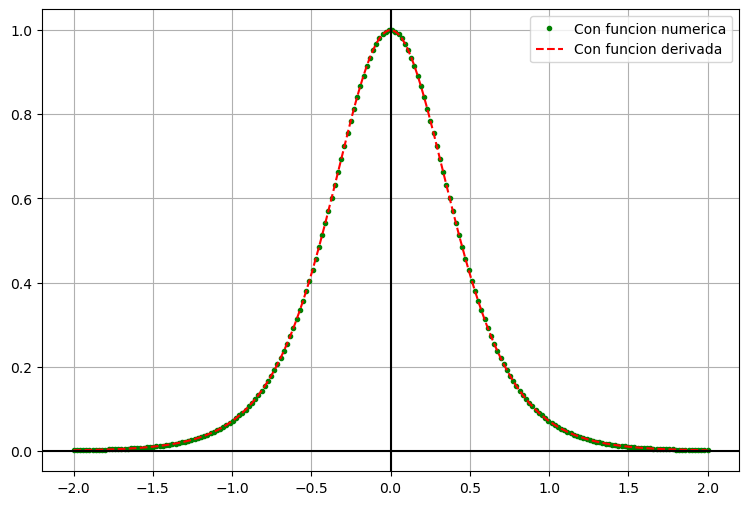

In [46]:
import matplotlib.pyplot as plt
import numpy as np
import math as mt
h=10**(-9)


X=np.linspace(-2,2,200)
Y=[]
for x in X:
    y=df(x)
    Y.append(y)

# Y=df(X)
Yn= sech(2*X)**2

plt.figure(figsize=(9,6))

plt.plot(X,Yn,".", color="green", label="Con funcion numerica")
plt.plot(X,Y,"r--", label="Con funcion derivada")
plt.axhline(y = 0.0, xmin = 0.0, color = 'black')
plt.axvline(x = 0.0, ymin = 0.0, color = 'black')
plt.legend()
plt.grid()


---
---

2. **Campo eléctrico de una distribución de cargas** (valor 3 puntos).

Supongamos que tenemos una distribución de cargas y queremos calcular el campo eléctrico resultante. Una forma de hacerlo es calcular primero el potencial eléctrico $\phi$ y luego tomar su gradiente.

Para una carga puntual $q$ en el origen, el potencial eléctrico a una distancia $r$ del origen es $\phi = q / 4\pi\epsilon_0 r$ y el campo eléctrico es $\vec{E} = -\nabla\phi$.

(a) Suponiendo que tienes dos cargas, de $+1\text{ C}$ y $-1\text{ C}$ (respectivamente), separadas $10\text{ cm}$. Calcula el potencial eléctrico resultante en un plano cuadrado de $1\text{ m} \times 1\text{ m}$ que rodea las cargas y pasa a través de ellas. Calcula el potencial en puntos espaciados a $1\text{ cm}$ en una cuadrícula y haz una visualización en la pantalla del potencial usando un gráfico de densidad.

<div align="center">
    <img src="img/t5e1a.png">
</div>

In [5]:
import numpy as np
def phi(q,r):
    e0= 8.85*10**(-12)
    return q/(4*np.pi*e0*r)

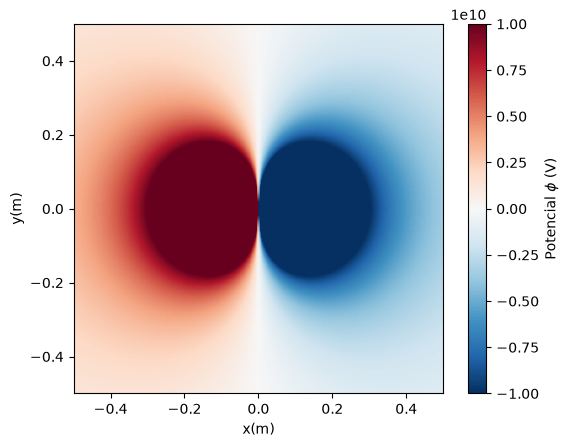

In [36]:
import matplotlib.pyplot as plt

d=0.1
q1= 1
x1, y1 = -d / 2, 0.0
q2=-1
x2, y2 =  d / 2, 0.0

x=np.linspace(-0.5,0.5,300)
y=np.linspace(-0.5,0.5,300)
X,Y=np.meshgrid(x,y)

r1= np.sqrt((X-x1)**2 +(Y-y1)**2)
r2= np.sqrt((X-x2)**2 +(Y-y2)**2)

P1= phi(q1,r1)
P2= phi(q2,r2)

P= P1+P2

plt.imshow(P, extent=[-0.5, 0.5, -0.5, 0.5], origin="lower", cmap="RdBu_r", vmin=-1e10, vmax=1e10)
plt.colorbar(label="Potencial $\phi$ (V)")
plt.xlabel("x(m)")
plt.ylabel("y(m)")
plt.show()


---
(b) Ahora calcula las derivadas parciales del potencial con respecto a $x$ y $y$, para encontrar el campo eléctrico en el plano $xy$ y realiza una visualización de dicho campo.

Lo anterior es un poco más complicado que visualizar el potencial, porque el campo eléctrico tiene **magnitud y dirección**. Una forma de hacerlo podría ser hacer dos gráficos de densidad, uno para la magnitud y otro para la dirección, este último usando el esquema de color "hsv" en pylab, que es un esquema de arcoíris que pasa por todos los colores pero comienza y termina con el mismo tono de rojo, lo que lo hace adecuado para representar cosas como direcciones o ángulos que dan la vuelta al círculo completo y terminan donde comenzaron. Una visualización más sofisticada podría usar el objeto de flecha del paquete visual, dibujando una cuadrícula de flechas con la dirección y la longitud elegidas para representar el campo.


In [50]:
import numpy as np
def phi(q,x,y):
    e0= 8.85*10**(-12)
    r=np.sqrt((x**2)+(y**2))
    return q/(4*np.pi*e0*r)

h=10**(-9)

def dpx(q,x,y):
    return(phi(q,x+h/2,y)-phi(q,x-h/2,y))/h

def dpy(q,x,y):
    return(phi(q,x,y+h/2)-phi(q,x,y-h/2))/h

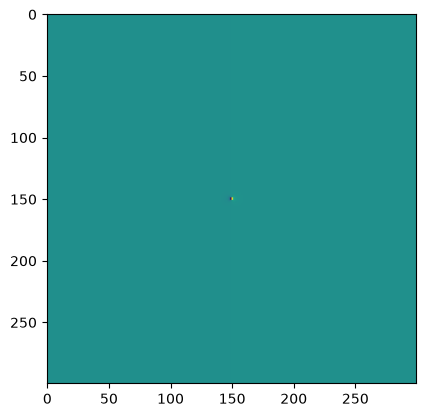

In [51]:
P1= phi(q1,X-x1,Y-y1)
P2= phi(q2,X-x2,Y-y2)

P= P1+P2

Px= dpx(q,X,Y)

plt.imshow(Px)

---
(c) Ahora supongamos que tenemos una distribución continua de carga sobre un cuadrado de $L \times L$. La densidad de carga en $\frac{\text{C}}{\text{m}^2}$ es:

$$ \sigma(x, y) = q_0 \sin \frac{2\pi x}{L} \sin \frac{2\pi y}{L}. $$

Calcula y visualiza el campo eléctrico resultante en puntos espaciados a $1\text{ cm}$ en 1 metro cuadrado del plano $xy$ para el caso donde $L = 10\text{ cm}$. La distribución de carga está centrada en el medio del área visualizada y $q_0 = 100\,\frac{\text{C}}{\text{m}^2}$.

Tendrás que realizar una integral doble sobre $x$ y $y$, luego diferenciar el potencial respecto a la posición para obtener el campo eléctrico. Elige cualquier método de integración que parezca apropiado para las integrales.